# Phase 1: Data Inspection and Preparation

In [2]:
import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current working directory: /Users/siri/Projects/cyclone-sensor-rag-system/Task1/notebooks
Files in current directory: ['task1_analysis.ipynb']


Step 1 — Load and inspect

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset
df = pd.read_excel(
    "../data/raw/data.xlsx",
    sheet_name="internship-data-1"
)

print(df.shape)
print(df.dtypes)
print(df.head())

/Users/siri/Projects/cyclone-sensor-rag-system/Task1/env1/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


(377719, 7)
time                        datetime64[us]
Cyclone_Inlet_Gas_Temp              object
Cyclone_Material_Temp               object
Cyclone_Outlet_Gas_draft            object
Cyclone_cone_draft                  object
Cyclone_Gas_Outlet_Temp             object
Cyclone_Inlet_Draft                 object
dtype: object
                 time Cyclone_Inlet_Gas_Temp Cyclone_Material_Temp  \
0 2017-01-01 00:00:00                 867.63                910.42   
1 2017-01-01 00:05:00                 879.23                918.14   
2 2017-01-01 00:10:00                 875.67                924.18   
3 2017-01-01 00:15:00                 875.28                923.15   
4 2017-01-01 00:20:00                 891.66                934.26   

  Cyclone_Outlet_Gas_draft Cyclone_cone_draft Cyclone_Gas_Outlet_Temp  \
0                  -189.54            -186.04                  852.13   
1                  -184.33             -182.1                  862.53   
2                  -181.26       

Step 2 — Validate the 6 sensor variables are present

In [7]:
sensor_cols = [
    "Cyclone_Inlet_Gas_Temp", "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft", "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp", "Cyclone_Inlet_Draft",
]
assert all(c in df.columns for c in sensor_cols)

Step 3 — Capture malformed values BEFORE coercing (for the quality report)

In [8]:
quality_rows = []
for c in sensor_cols:
    is_str = df[c].apply(lambda x: isinstance(x, str))
    vc = df.loc[is_str, c].value_counts()
    for val, cnt in vc.items():
        quality_rows.append({"column": c, "issue_type": "non_numeric_value", "value": val, "count": cnt})
    print(c, "non-numeric count:", is_str.sum())

Cyclone_Inlet_Gas_Temp non-numeric count: 1320
Cyclone_Material_Temp non-numeric count: 1591
Cyclone_Outlet_Gas_draft non-numeric count: 1321
Cyclone_cone_draft non-numeric count: 1320
Cyclone_Gas_Outlet_Temp non-numeric count: 1321
Cyclone_Inlet_Draft non-numeric count: 1322


Step 4 — Convert to numeric (fault-code strings become NaN)

In [9]:
for c in sensor_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

Step 5 — Duplicate timestamps (confirm none, but keep the check — don’t assume)

In [10]:
dupe_count = df["time"].duplicated().sum()
quality_rows.append({"column": "time", "issue_type": "duplicate_timestamps", "value": None, "count": dupe_count})
df = df.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)

Step 6 — Reindex onto a strict 5-minute grid (this materializes the gaps)

In [11]:
df = df.set_index("time")
full_index = pd.date_range(df.index.min(), df.index.max(), freq="5min")
df = df.reindex(full_index)
df.index.name = "time"

Step 7 — Identify and classify gaps

In [13]:
is_missing = df[sensor_cols].isna().all(axis=1)
gap_id = (is_missing != is_missing.shift()).cumsum()
gap_events = (
    df[is_missing].groupby(gap_id[is_missing])
    .apply(lambda g: pd.Series({"start": g.index.min(), "end": g.index.max(), "n_slots": len(g)}))
)
print(gap_events)   # should show 3 events of ~287 slots each, on the three Dec-31 dates

                  start                 end  n_slots
2   2017-01-09 13:55:00 2017-01-09 15:35:00       21
4   2017-01-10 23:05:00 2017-01-11 01:30:00       30
6   2017-01-20 10:25:00 2017-01-20 10:25:00        1
8   2017-02-23 09:20:00 2017-02-23 09:25:00        2
10  2017-02-23 09:35:00 2017-02-23 09:55:00        5
..                  ...                 ...      ...
156 2019-12-11 09:20:00 2019-12-11 09:20:00        1
158 2019-12-26 10:05:00 2019-12-26 10:05:00        1
160 2019-12-27 10:05:00 2019-12-27 11:00:00       12
162 2019-12-31 00:05:00 2019-12-31 23:55:00      287
164 2020-01-29 19:25:00 2020-01-29 21:15:00       23

[82 rows x 3 columns]


Step 8 — Flag the 3 structural outage days, handle missing values differently for each case

In [14]:
df["is_data_gap"] = False
for _, row in gap_events.iterrows():
    df.loc[row["start"]:row["end"], "is_data_gap"] = True

# Short, scattered NaNs (fault codes) -> time-based interpolation, capped so it can't bridge the big gaps
df[sensor_cols] = df[sensor_cols].interpolate(method="time", limit=6, limit_direction="both")

remaining_na = df[sensor_cols].isna().sum()
print(remaining_na)   # should now be close to 861 per column — the 3 outage days, left as NaN on purpose

Cyclone_Inlet_Gas_Temp      1703
Cyclone_Material_Temp       1703
Cyclone_Outlet_Gas_draft    1703
Cyclone_cone_draft          1703
Cyclone_Gas_Outlet_Temp     1703
Cyclone_Inlet_Draft         1703
dtype: int64


Step 9 — Outlier investigation (document, don’t blindly delete)

In [15]:
outlier_summary = []
for c in sensor_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    outlier_summary.append({"column": c, "q1": q1, "q3": q3, "lower_bound": lo, "upper_bound": hi, "n_outliers_iqr3": n_out})
    quality_rows.append({"column": c, "issue_type": "outlier_count_iqr3", "value": f"[{lo:.1f}, {hi:.1f}]", "count": n_out})
pd.DataFrame(outlier_summary)

,column,q1,q3,lower_bound,upper_bound,n_outliers_iqr3
0,Cyclone_Inlet_Gas_Temp,856.22,901.11,721.55,1035.78,80057
1,Cyclone_Material_Temp,867.58,943.64,639.40,1171.82,76954
2,Cyclone_Outlet_Gas_draft,-247.19,-170.02,-478.70,61.49,0
3,Cyclone_cone_draft,-226.77,-143.46,-476.70,106.47,2
4,Cyclone_Gas_Outlet_Temp,801.62,899.29,508.61,1192.30,74998
5,Cyclone_Inlet_Draft,-193.50,-136.19,-365.43,35.74,7


Step 10 — Summary statistics and correlation matrix

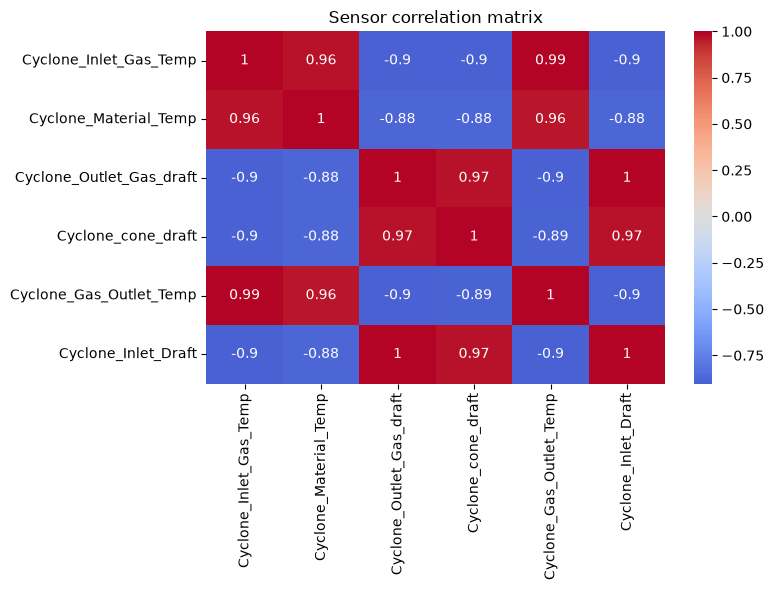

In [17]:
summary_stats = df[sensor_cols].describe()
corr = df[sensor_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Sensor correlation matrix")
plt.tight_layout()
plt.savefig("../plots/correlation_heatmap.png", dpi=150)

Step 11 — One-week and one-year visualizations

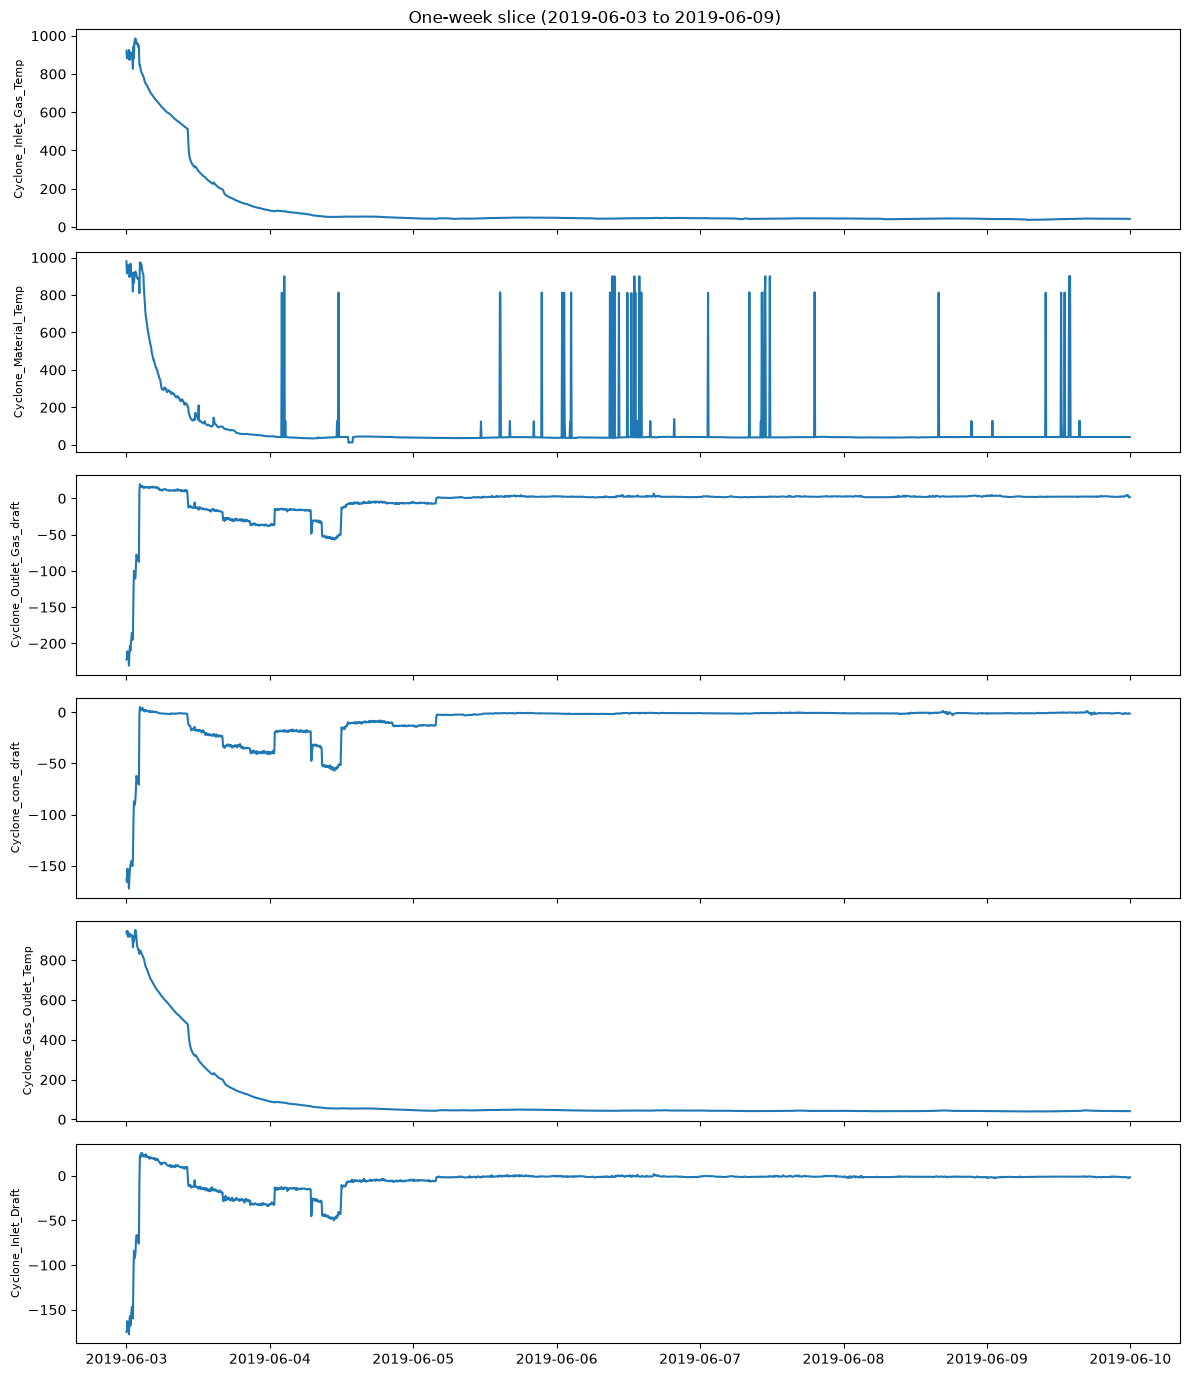

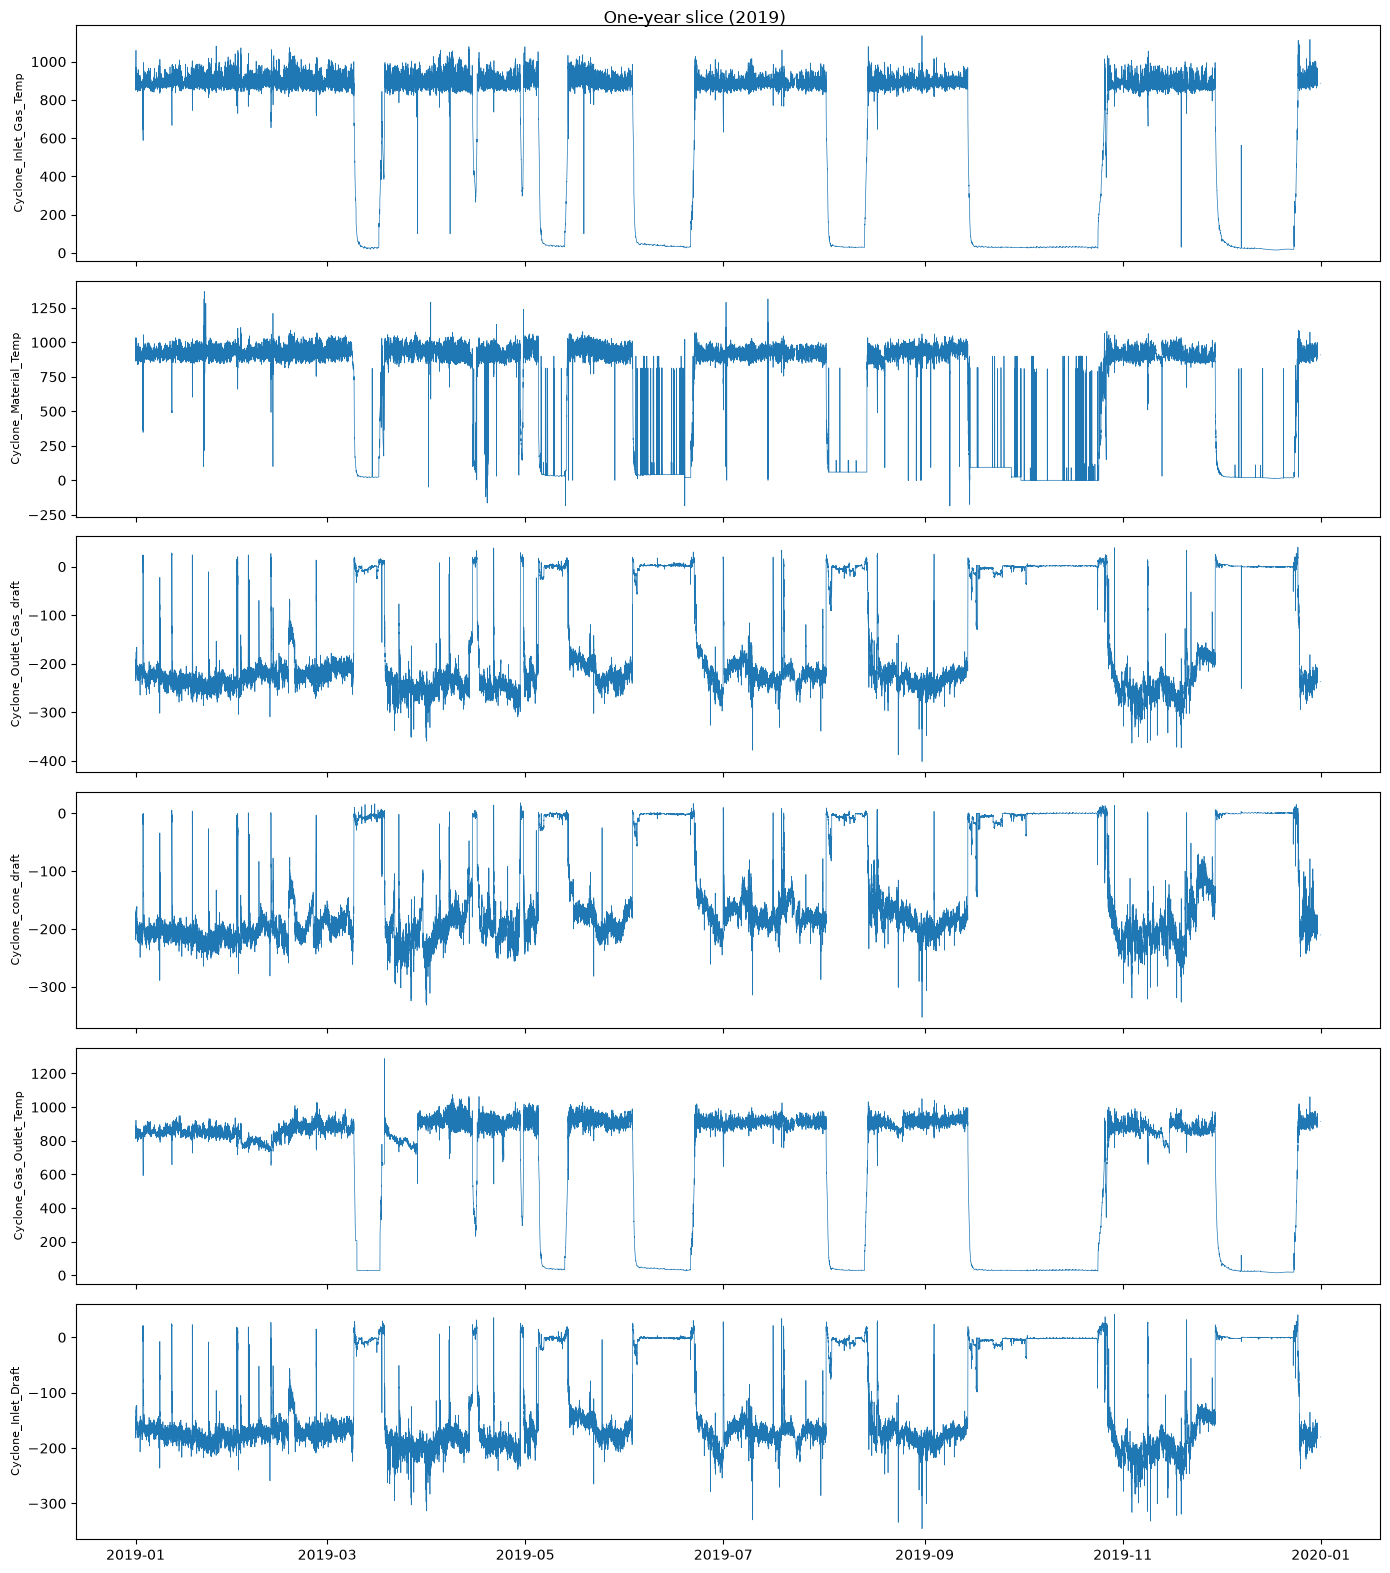

In [20]:
week = df.loc["2019-06-03":"2019-06-09"]
fig, axes = plt.subplots(len(sensor_cols), 1, figsize=(12, 14), sharex=True)
for ax, c in zip(axes, sensor_cols):
    ax.plot(week.index, week[c]); ax.set_ylabel(c, fontsize=8)
plt.suptitle("One-week slice (2019-06-03 to 2019-06-09)")
plt.tight_layout()
plt.savefig("../plots/weekly_slice.png", dpi=150)

year = df.loc["2019-01-01":"2019-12-31"]
fig, axes = plt.subplots(len(sensor_cols), 1, figsize=(14, 16), sharex=True)
for ax, c in zip(axes, sensor_cols):
    ax.plot(year.index, year[c], linewidth=0.5); ax.set_ylabel(c, fontsize=8)
plt.suptitle("One-year slice (2019)")
plt.tight_layout()
plt.savefig("../plots/yearly_slice.png", dpi=150)

Step 12 — Write deliverables

In [22]:
df.reset_index().to_csv("../outputs/cleaned_data.csv", index=False)
pd.DataFrame(quality_rows).to_csv("../outputs/data_quality_report.csv", index=False)
summary_stats.to_csv("../outputs/summary_statistics.csv")

Step 13 — Sanity checks before moving on

In [23]:
assert df.index.is_monotonic_increasing
assert (df.index.to_series().diff().dropna() == pd.Timedelta(minutes=5)).all()
print("Final shape:", df.shape)
print("Rows still NaN (should be ~861, the 3 outage days):", df[sensor_cols].isna().any(axis=1).sum())

Final shape: (378580, 7)
Rows still NaN (should be ~861, the 3 outage days): 1703
